# Week 2 Day 4: Normalise & Scale the Loan Dataset

Input: `data/featured_loan_dataset.csv` (output of W2D3).

## Scaling decisions
- **Scaler chosen: `StandardScaler`.** The planned models (logistic regression, later possibly gradient-based models) are sensitive to feature scale; standardising gives every feature mean 0 and standard deviation 1.
- **Fit on the training split only.** The data is split 80/20 (stratified) first, and the scaler learns its mean and standard deviation from the training rows alone. Fitting on all rows would leak information from the test set.
- **Columns scaled:** the 7 continuous numeric features. `Credit_History` (0/1) and the text columns are left alone.
- **`MinMaxScaler` is not needed** because none of the planned models requires inputs in [0, 1]; it is shown below only as a comparison.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

candidates = [Path("data/featured_loan_dataset.csv"), Path("../data/featured_loan_dataset.csv")]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    import os
    raise FileNotFoundError(f"CSV not found. Current folder is: {os.getcwd()}")
project_root = csv_path.parent.parent

df = pd.read_csv(csv_path)
df["Loan_Status_num"] = (df["Loan_Status"] == "Y").astype(int)
df.shape

(614, 18)

## 1. Split first, then scale

In [2]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
            "TotalIncome", "LogTotalIncome", "LoanAmount_to_Income"]
X = df[num_cols]
y = df["Loan_Status_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("train:", X_train.shape, "test:", X_test.shape)
X_train.describe().round(2)

train: (491, 7) test: (123, 7)


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,TotalIncome,LogTotalIncome,LoanAmount_to_Income
count,491.00,491.00,491.00,491.00,491.00,491.00,491.00
mean,5530.00,1569.54,146.52,341.74,7099.54,8.68,0.02
std,6457.78,2789.52,85.39,65.11,6692.76,0.54,0.01
min,210.00,0.00,9.00,12.00,1442.00,7.27,0.00
25%,2906.00,0.00,100.50,360.00,4177.00,8.34,0.02
50%,3859.00,1032.00,128.00,360.00,5391.00,8.59,0.02
75%,5825.00,2241.00,165.00,360.00,7550.50,8.93,0.03
max,81000.00,41667.00,700.00,480.00,81000.00,11.30,0.08


## 2. Fit StandardScaler on the training data

In [3]:
scaler = StandardScaler().fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=num_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=num_cols, index=X_test.index)

print("Train after scaling (mean, std):")
print(X_train_scaled.agg(["mean", "std"]).round(2))
print()
print("Test after scaling (mean, std) - close to, but not exactly, 0 and 1:")
print(X_test_scaled.agg(["mean", "std"]).round(2))

Train after scaling (mean, std):
      ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
mean             -0.0                0.0        -0.0              -0.0   
std               1.0                1.0         1.0               1.0   

      TotalIncome  LogTotalIncome  LoanAmount_to_Income  
mean          0.0             0.0                   0.0  
std           1.0             1.0                   1.0  

Test after scaling (mean, std) - close to, but not exactly, 0 and 1:
      ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
mean            -0.10               0.09       -0.05              0.05   
std              0.69               1.23        0.93              0.95   

      TotalIncome  LogTotalIncome  LoanAmount_to_Income  
mean        -0.06           -0.08                  0.18  
std          0.81            1.02                  1.33  


## 3. Before vs after: histograms side by side

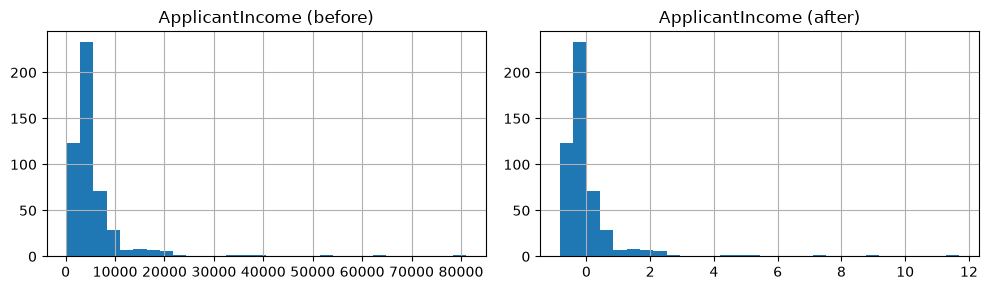

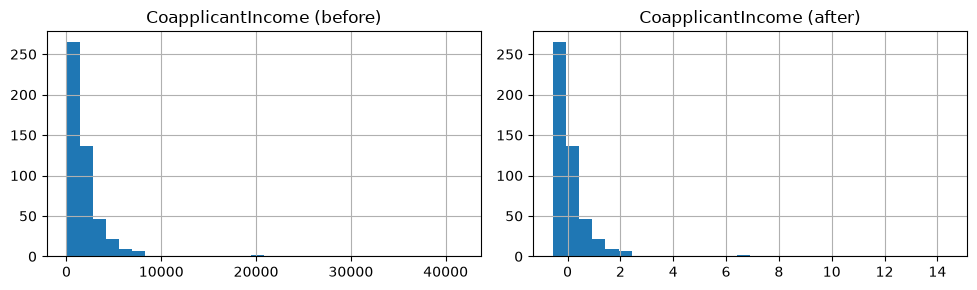

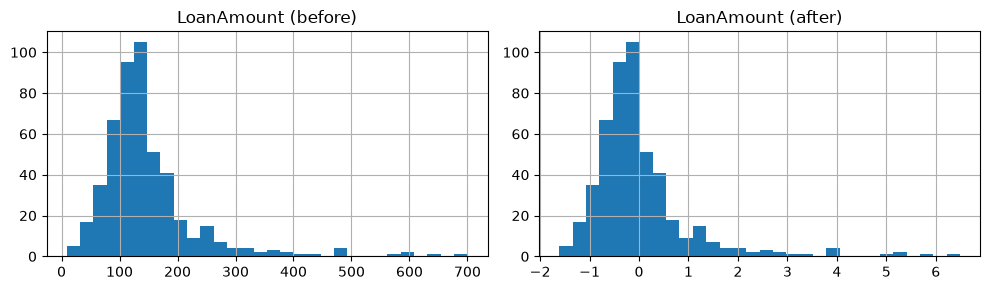

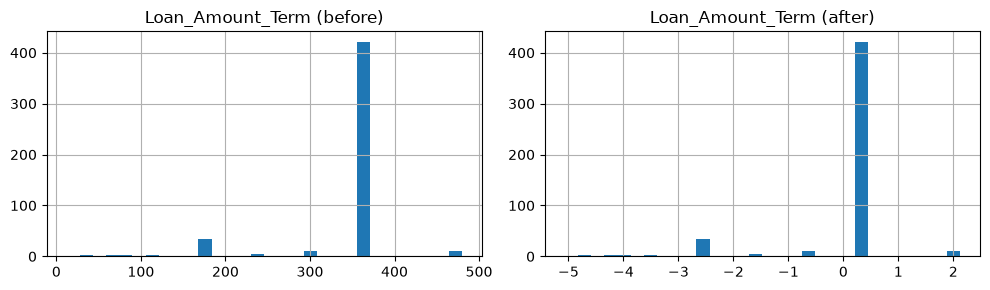

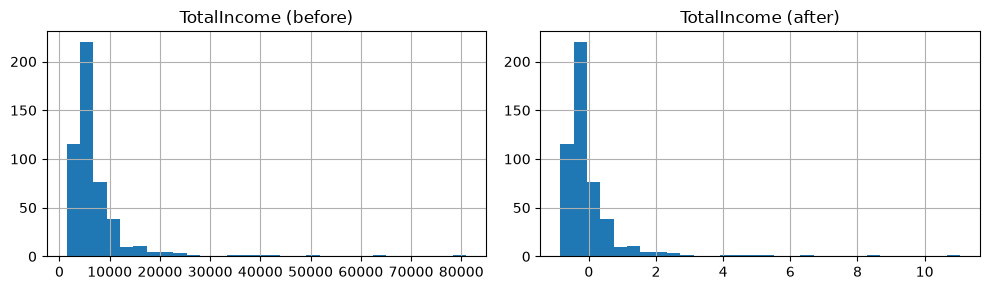

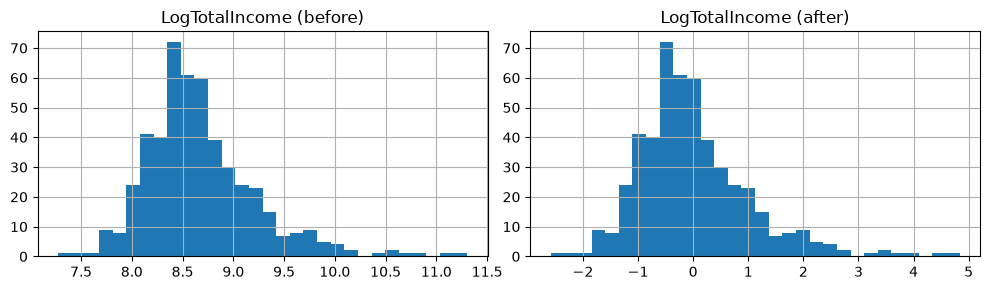

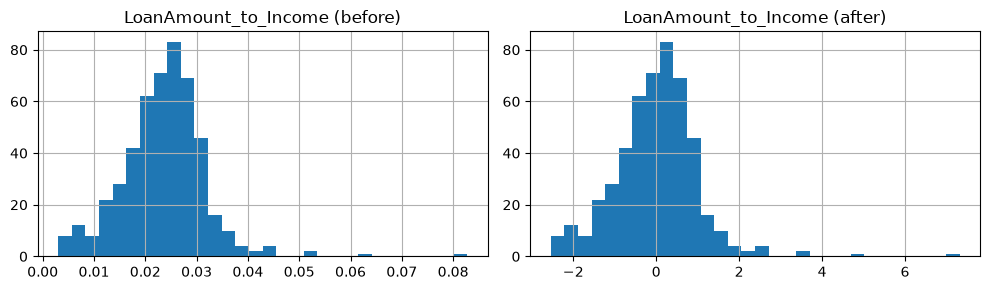

In [4]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    X_train[col].hist(bins=30, ax=axes[0]); axes[0].set_title(f"{col} (before)")
    X_train_scaled[col].hist(bins=30, ax=axes[1]); axes[1].set_title(f"{col} (after)")
    plt.tight_layout()
    plt.show()

In [5]:
skew = pd.DataFrame({
    "skew_before": X_train.skew(),
    "skew_after": X_train_scaled.skew(),
}).round(2)
skew

,skew_before,skew_after
ApplicantIncome,6.55,6.55
CoapplicantIncome,7.61,7.61
LoanAmount,2.79,2.79
Loan_Amount_Term,-2.47,-2.47
TotalIncome,5.78,5.78
LogTotalIncome,1.17,1.17
LoanAmount_to_Income,0.95,0.95


## 4. MinMaxScaler for comparison (not saved)

In [6]:
mm = MinMaxScaler().fit(X_train[["LoanAmount_to_Income"]])
train_mm = mm.transform(X_train[["LoanAmount_to_Income"]])
test_mm = mm.transform(X_test[["LoanAmount_to_Income"]])
print("train range:", train_mm.min().round(3), "to", train_mm.max().round(3))
print("test range: ", test_mm.min().round(3), "to", test_mm.max().round(3))

train range: 0.0 to 1.0
test range:  -0.006 to 0.84


## 5. Save the fitted scaler

In [7]:
models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)
scaler_path = models_dir / "scaler.pkl"
joblib.dump(scaler, scaler_path)

# verify it reloads and gives identical results
reloaded = joblib.load(scaler_path)
assert np.allclose(reloaded.transform(X_test), X_test_scaled.values)
print("Saved", scaler_path, "- reload check passed")

Saved ..\models\scaler.pkl - reload check passed


## Findings
- After `StandardScaler`, every training feature has mean 0 and standard deviation 1, so income (hundreds to tens of thousands) and ratios (about 0.02) are now on the same scale.
- The test set comes out close to, but not exactly, 0 and 1 (for example `LoanAmount_to_Income` has std about 1.3), because it is scaled with the training statistics. That is correct and shows no information leaked from the test set.
- Scaling does not change the shape of a distribution: skew is identical before and after (`ApplicantIncome` 6.55, `LogTotalIncome` 1.17). The log transform from W2D3, not the scaler, is what reduces skew, so `LogTotalIncome` is the better income feature for linear models.
- With `MinMaxScaler`, test values can fall slightly outside [0, 1] (minimum about -0.006), another reason it is only a comparison here.
- The fitted scaler is saved to `models/scaler.pkl` for the W2D5 pipeline and for serving.